# Async Programming with asyncio

Many programs spend most of their time **waiting**: for a web server, a database or an LLM API. **Asynchronous programming** lets one thread start many waiting operations and continue with other work while they wait. Python's `asyncio` module provides this model with the keywords `async` and `await`.

**After this lesson you can:**

1. Explain coroutines, the event loop and `await`.
2. Run operations concurrently with `asyncio.gather` and `TaskGroup`.
3. Limit concurrency with a semaphore and add timeouts.
4. Measure the speed-up for real network requests.

The experiments use a real HTTP server that this notebook starts on your machine. Each response takes 200 ms, like a slow API.

## 1. Coroutines and the Event Loop

- `async def` defines a **coroutine function**. Calling it returns a coroutine object; the body does not run yet.
- `await x` pauses the coroutine until `x` is ready. While it waits, the **event loop** runs other coroutines.
- `asyncio.run(main())` starts an event loop in a normal script. In Jupyter, an event loop already runs, so you use `await main()` directly in a cell.

Async helps only for **I/O-bound** work. CPU-bound work still blocks the loop; use processes for it (M01 Lesson 17).

In [1]:
import asyncio
import time

async def make_tea(name: str, minutes: float) -> str:
    print(f"start {name}")
    await asyncio.sleep(minutes)          # waiting: the event loop runs other coroutines
    print(f"done  {name}")
    return name

t = time.perf_counter()
results = await asyncio.gather(make_tea("black tea", 0.3), make_tea("green tea", 0.2), make_tea("herbal tea", 0.1))
print(results, f"in {time.perf_counter() - t:.2f} s (not 0.6 s)")

start black tea
start green tea
start herbal tea
done  herbal tea
done  green tea


done  black tea
['black tea', 'green tea', 'herbal tea'] in 0.30 s (not 0.6 s)


The three coroutines waited at the same time, so the total time is the longest wait (0.3 s), not the sum.

## 2. A Real HTTP Server for the Experiments

The cell starts a small HTTP server in a background thread. It answers `GET /items/<n>` with JSON after a delay of 200 ms. The client side uses only the standard library: `asyncio.open_connection` sends a raw HTTP/1.1 request over a TCP socket.

In [2]:
import json
import threading
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer

class SlowAPI(BaseHTTPRequestHandler):
    def do_GET(self):
        time.sleep(0.2)                                         # the "slow backend"
        item = int(self.path.rsplit("/", 1)[-1])
        body = json.dumps({"item": item, "price": round(item * 1.5, 2)}).encode()
        self.send_response(200)
        self.send_header("Content-Type", "application/json")
        self.send_header("Content-Length", str(len(body)))
        self.end_headers()
        try:
            self.wfile.write(body)
        except (BrokenPipeError, ConnectionResetError):        # the client gave up (for example after a timeout)
            pass

    def log_message(self, *args):                               # keep the notebook output clean
        pass

class Server(ThreadingHTTPServer):
    request_queue_size = 256       # the default backlog of 5 drops bursts of connections

server = Server(("127.0.0.1", 0), SlowAPI)                      # port 0 = any free port
PORT = server.server_address[1]
threading.Thread(target=server.serve_forever, daemon=True).start()

async def fetch(item: int) -> dict:
    reader, writer = await asyncio.open_connection("127.0.0.1", PORT)
    writer.write(f"GET /items/{item} HTTP/1.1\r\nHost: localhost\r\nConnection: close\r\n\r\n".encode())
    await writer.drain()
    raw = await reader.read()
    writer.close()
    await writer.wait_closed()
    return json.loads(raw.split(b"\r\n\r\n", 1)[1])

print(f"server on port {PORT}:", await fetch(7))

server on port 44701: {'item': 7, 'price': 10.5}


## 3. Sequential vs Concurrent Requests

`asyncio.gather(*coroutines)` runs all coroutines concurrently and returns the results **in the same order** as the inputs. Python 3.11 added `asyncio.TaskGroup`: if one task fails, the group cancels the others and raises the errors together (as an `ExceptionGroup`, M01 Lesson 10).

In [3]:
async def sequential(n):
    return [await fetch(i) for i in range(n)]

async def concurrent_gather(n):
    return await asyncio.gather(*(fetch(i) for i in range(n)))

async def concurrent_taskgroup(n):
    async with asyncio.TaskGroup() as tg:
        tasks = [tg.create_task(fetch(i)) for i in range(n)]
    return [t.result() for t in tasks]

for name, fn in [("sequential", sequential), ("gather", concurrent_gather), ("TaskGroup", concurrent_taskgroup)]:
    t = time.perf_counter()
    data = await fn(10)
    print(f"{name:<11} 10 requests in {time.perf_counter() - t:5.2f} s | prices: {[d['price'] for d in data][:5]} ...")

sequential  10 requests in  2.02 s | prices: [0.0, 1.5, 3.0, 4.5, 6.0] ...


gather      10 requests in  0.21 s | prices: [0.0, 1.5, 3.0, 4.5, 6.0] ...


TaskGroup   10 requests in  0.21 s | prices: [0.0, 1.5, 3.0, 4.5, 6.0] ...


## 4. Limit Concurrency and Add Timeouts

Real APIs have **rate limits**, and too many open connections can overload your own machine. An `asyncio.Semaphore` allows at most *k* coroutines in a section at the same time. `asyncio.timeout()` (Python 3.11) cancels an operation that takes too long.

In [4]:
async def fetch_limited(item: int, sem: asyncio.Semaphore) -> dict:
    async with sem:                                   # at most k requests in flight
        return await fetch(item)

async def run_with_limit(n: int, k: int) -> float:
    sem = asyncio.Semaphore(k)
    t = time.perf_counter()
    await asyncio.gather(*(fetch_limited(i, sem) for i in range(n)))
    return time.perf_counter() - t

print(f"40 requests, at most 5 at a time : {await run_with_limit(40, 5):.2f} s (expected about 40/5 * 0.2 = 1.6 s)")

try:
    async with asyncio.timeout(0.1):                  # the server needs 0.2 s
        await fetch(1)
except TimeoutError:
    print("request cancelled after 0.1 s")

40 requests, at most 5 at a time : 1.63 s (expected about 40/5 * 0.2 = 1.6 s)
request cancelled after 0.1 s


## 5. Measure the Speed-up

The experiment sends $n$ requests sequentially and concurrently and plots the total time.

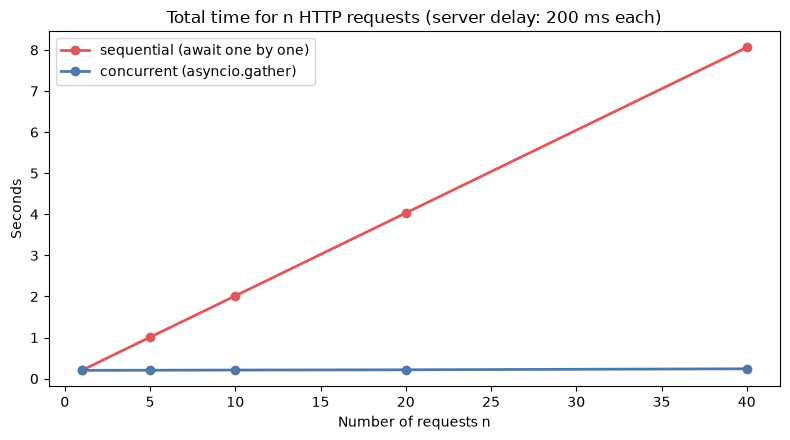

n =  1: sequential  0.20 s | concurrent 0.20 s | speed-up   1.0x
n =  5: sequential  1.01 s | concurrent 0.20 s | speed-up   4.9x
n = 10: sequential  2.01 s | concurrent 0.21 s | speed-up   9.7x
n = 20: sequential  4.03 s | concurrent 0.21 s | speed-up  18.8x
n = 40: sequential  8.06 s | concurrent 0.24 s | speed-up  33.6x


In [5]:
import matplotlib.pyplot as plt

ns = [1, 5, 10, 20, 40]
seq_t, conc_t = [], []
for n in ns:
    t = time.perf_counter(); await sequential(n); seq_t.append(time.perf_counter() - t)
    t = time.perf_counter(); await concurrent_gather(n); conc_t.append(time.perf_counter() - t)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ns, seq_t, marker="o", lw=2, color="#E15759", label="sequential (await one by one)")
ax.plot(ns, conc_t, marker="o", lw=2, color="#4E79A7", label="concurrent (asyncio.gather)")
ax.set(title="Total time for n HTTP requests (server delay: 200 ms each)", xlabel="Number of requests n",
       ylabel="Seconds")
ax.legend()
plt.tight_layout()
plt.show()
for n, a, b in zip(ns, seq_t, conc_t):
    print(f"n = {n:>2}: sequential {a:5.2f} s | concurrent {b:4.2f} s | speed-up {a / b:5.1f}x")
server.shutdown()

The sequential time grows linearly: $n \times 0.2$ s. The concurrent time stays close to 0.2 s, because all requests wait at the same time. The speed-up grows with $n$ until the server or the network becomes the limit.

*Insight: Use `asyncio` when a program waits for many independent I/O operations: API calls, database queries, LLM requests. Use `async` libraries (httpx, asyncpg, the async clients of LLM SDKs) inside it, because one blocking call stops the whole event loop.*

## Real-World Use Case or Analogy

Async code is like **one waiter in a restaurant** who serves many tables. The waiter takes an order, gives it to the kitchen and goes to the next table instead of standing at the kitchen door until the food is ready. One waiter can serve ten tables, because most of the time is spent waiting for the kitchen.

FastAPI (M30) runs `async def` endpoints on an event loop, so one server process handles thousands of open connections. LLM applications use `asyncio.gather` to send many prompts in parallel, with a semaphore to respect the provider's rate limit (M29, M31).